# Prática 4 — AutoML versus meta-aprendizagem (regressão desbalanceada)

Mesmo problema, medida e protocolo das Práticas 1–3: 30 datasets de regressão
desbalanceada, **SERA** (menor é melhor) e as mesmas **dez partições** (KFold,
`shuffle`, semente 42). O AutoML recebe só o treino de cada fold.

As execuções pesadas ficam em scripts (`executar_baselines.py`,
`executar_warmstart.py`, `executar_automl.py`, encadeados por `rodar_tudo.sh`);
este notebook só lê os resultados brutos de `resultados/` e faz as análises.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import friedmanchisquare, spearmanr, studentized_range
import scikit_posthocs as sp

import comum as c
sys.path.insert(0, str(c.BASE / 'codigo'))
from abordagens_meta_modelo import abordagem2_regressor_sobre_R
from gerar_X import extrair_meta_features

R = c.SAIDA
FIG = R / 'figuras'; FIG.mkdir(exist_ok=True)
DATASETS = c.datasets()
pd.set_option('display.width', 160)
print(json.dumps(c.ambiente(), indent=1))

{
 "cpu": "Apple M2",
 "nucleos": 8,
 "memoria_gb": 8.0,
 "python": "3.11.18",
 "sistema": "macOS-27.2.1-arm64-arm-64bit"
}


## 1. Resultados brutos por fold

In [2]:
base = pd.read_csv(R / 'base_por_fold.csv')
desreg = pd.read_csv(R / 'desreg_por_fold.csv')
ws = pd.read_csv(R / 'warmstart_por_fold.csv')
ws['segundos'] = ws.segundos_busca + ws.segundos_final + ws.segundos_iniciais / c.FOLDS

linhas = []
for arq in sorted((R / 'automl').glob('*.jsonl')):
    linhas += [json.loads(l) for l in arq.read_text().splitlines()]
automl = pd.DataFrame(linhas)
falhas = automl[automl.erro.notna()]
automl = automl[automl.erro.isna()].drop_duplicates(['sistema', 'orcamento', 'dataset', 'fold'], keep='last')
automl['metodo'] = automl.sistema + '_' + automl.orcamento.astype(str) + 's'
print('falhas registradas (reexecutadas depois):', len(falhas))
display(automl.groupby(['sistema', 'orcamento']).agg(execucoes=('sera', 'size'),
        segundos_medios=('segundos', 'mean'), segundos_max=('segundos', 'max')).round(1))
assert (automl.groupby('metodo').size() == 300).all(), 'há execuções faltando'

falhas registradas (reexecutadas depois): 28


execucoes  segundos_medios  segundos_max
sistema    orcamento                                          
autogluon  5                300              8.3          26.7
           30               300             26.2          35.8
           120              300             65.4         128.6
flaml      5                300              5.7          24.2
           30               300             31.0          54.9
flaml_meta 5                300              8.8          73.3
           30               300             32.6          82.2
           120              300            111.4         178.6

**Mesmo protocolo de fato.** A matriz P das práticas anteriores foi gerada por nós,
nas mesmas partições; ainda assim os seis regressores foram reexecutados aqui
(scikit-learn {versão atual}), junto com o AutoML, para que tempos e perdas venham
do mesmo ambiente. A conferência abaixo compara com a P original.

In [3]:
P = base.pivot_table(index='dataset', columns='metodo', values='sera').loc[DATASETS, c.ALGORITMOS]
P_antiga = pd.read_csv(c.META / 'P.csv', index_col=0).loc[DATASETS, c.ALGORITMOS]
dif = (P / P_antiga - 1).abs()
print('diferença relativa mediana com a P da Prática 1:', f'{dif.stack().median():.2e}',
      '| máxima:', f'{dif.stack().max():.3f}')
print('o melhor algoritmo coincide em', int((P.idxmin(axis=1) == P_antiga.idxmin(axis=1)).sum()), 'de 30 datasets')
Rk = P.rank(axis=1)

diferença relativa mediana com a P da Prática 1: 2.50e-07 | máxima: 0.184
o melhor algoritmo coincide em 30 de 30 datasets


## 2. Os métodos comparados

1. **Melhor médio** — algoritmo de melhor rank médio nos outros 29 datasets, configuração padrão.
2. **MtL** — Abordagem 2 da Prática 1 (RF sobre R, com Xbase; Xestendido não trouxe ganho na Prática 2),
   *leave-one-dataset-out*, top-1, configuração padrão.
3. **Warm-start** — SMBO da Prática 3 (Xestendido, k=3, T=20) com avaliação interna no treino do fold.
4. **AutoML** — FLAML (com e sem meta-conhecimento) e AutoGluon, em 5, 30 e 120 s por fold.
5. **Oráculo** — melhor dos seis algoritmos de P no dataset (teto da seleção, não é método).

Extra, ligado ao tema da pesquisa: **DESReg** (seleção dinâmica sobre o pool de bagging
dos seis regressores), com competência padrão e com competência ponderada pela relevância (`phi`).

In [4]:
Xbase = pd.read_csv(c.META / 'X.csv', index_col=0).loc[DATASETS]
rec, custo_rec = {}, {}
import time
for alvo in DATASETS:
    t0 = time.perf_counter()
    mf = extrair_meta_features(c.DADOS / f'{alvo}.csv')           # custo online: meta-características
    t_mf = time.perf_counter() - t0
    t0 = time.perf_counter()
    ranking = abordagem2_regressor_sobre_R(Xbase.drop(index=alvo), Rk.drop(index=alvo), Xbase.loc[[alvo]]).loc[alvo]
    t_mm = time.perf_counter() - t0                                  # treinar/consultar o meta-modelo (29 linhas)
    rec[alvo] = ranking.idxmin()
    custo_rec[alvo] = dict(meta_caracteristicas=t_mf, meta_modelo=t_mm)
rec = pd.Series(rec, name='MtL')
melhor_medio = pd.Series({d: Rk.drop(index=d).mean().idxmin() for d in DATASETS}, name='Melhor_medio')
display(pd.concat([melhor_medio, rec, P.idxmin(axis=1).rename('Oraculo')], axis=1).T)

/Users/carlosh/me/mestrado/meta-learn/projeto-01/pratica-04/.venv/lib/python3.11/site-packages/pandas/core/apply.py:1081: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  results[i] = self.func(v, *self.args, **self.kwargs)
/Users/carlosh/me/mestrado/meta-learn/projeto-01/pratica-04/.venv/lib/python3.11/site-packages/pandas/core/apply.py:1081: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  results[i] = self.func(v, *self.args, **self.kwargs)


,a1,a2,a3,a7,abalone,acceleration,airfoild,analcatdata_apnea3,available_power,boston,...,lungcancer_shedden,maximal_torque,meta,mortgage,pdgfr,sensory,space_ga,treasury,triazines,wine_quality
Melhor_medio,RF,RF,RF,RF,RF,RF,RF,RF,RF,RF,...,RF,RF,RF,RF,RF,RF,RF,RF,RF,RF
MtL,RF,RF,GB,RF,RF,GB,RF,RF,GB,RF,...,RF,RF,GB,RF,RF,RF,RF,GB,GB,RF
Oraculo,GB,RF,RF,RF,RF,RF,DT,RF,RF,GB,...,Linear,GB,Linear,Linear,GB,RF,SVR,Linear,RF,RF


In [5]:
def por_fold(algs: pd.Series, nome):
    m = base.merge(algs.rename('alg').reset_index().rename(columns={'index': 'dataset'}), on='dataset')
    m = m[m.metodo == m.alg].assign(metodo=nome)
    return m[['dataset', 'fold', 'metodo', 'sera', 'segundos']]

oraculo = P.idxmin(axis=1)
folds = pd.concat([
    por_fold(melhor_medio, 'Melhor_medio'),
    por_fold(rec, 'MtL'),
    ws.assign(metodo='Warm-start')[['dataset', 'fold', 'metodo', 'sera', 'segundos']],
    desreg[['dataset', 'fold', 'metodo', 'sera', 'segundos']],
    automl[['dataset', 'fold', 'metodo', 'sera', 'segundos']],
    por_fold(oraculo, 'Oraculo'),
])
# custo online da recomendação: meta-características e meta-modelo, uma vez por dataset (rateado nos folds)
extra = pd.DataFrame(custo_rec).T.sum(axis=1) / c.FOLDS
folds.loc[folds.metodo == 'MtL', 'segundos'] += folds.loc[folds.metodo == 'MtL', 'dataset'].map(extra).to_numpy()
folds.to_csv(R / 'todos_por_fold.csv', index=False)

L = folds.pivot_table(index='dataset', columns='metodo', values='sera').loc[DATASETS]
TEMPO = folds.pivot_table(index='dataset', columns='metodo', values='segundos').loc[DATASETS]
METODOS_FIXOS = ['Melhor_medio', 'MtL', 'Warm-start', 'DESReg', 'DESReg_phi']
AUTOML = sorted(automl.metodo.unique(), key=lambda m: (m.split('_')[0], int(m.split('_')[-1][:-1]), m))

## 3. Análise 1 — desempenho

In [6]:
# Perda relativa ao melhor resultado observado no dataset (entre todos os métodos e o oráculo)
melhor = L.min(axis=1)
REL = L.div(melhor, axis=0) - 1
resumo = pd.DataFrame({'perda_rel_media': REL.mean(), 'perda_rel_mediana': REL.median(),
                       'rank_medio': L.drop(columns='Oraculo').rank(axis=1).mean(),
                       'vitorias': (L.drop(columns='Oraculo').rank(axis=1) == 1).sum(),
                       'segundos_por_fold': TEMPO.mean()}).sort_values('rank_medio')
display(resumo.round(3))
resumo.to_csv(R / 'resumo_metodos.csv')
L.to_csv(R / 'sera_por_dataset.csv'); REL.to_csv(R / 'perda_relativa_por_dataset.csv')

,perda_rel_media,perda_rel_mediana,rank_medio,vitorias,segundos_por_fold
metodo,,,,,
autogluon_120s,0.210,0.020,4.333,8.0,65.434
autogluon_30s,0.413,0.123,5.033,1.0,26.169
Warm-start,2.008,0.279,5.900,0.0,27.204
flaml_meta_120s,1.457,0.159,6.467,3.0,111.446
Melhor_medio,2.105,0.300,6.533,0.0,1.496
flaml_meta_30s,1.485,0.178,6.783,3.0,32.613
MtL,2.116,0.319,6.833,0.0,1.269
flaml_meta_5s,1.516,0.288,7.083,1.0,8.756
flaml_30s,0.410,0.195,7.317,1.0,31.013


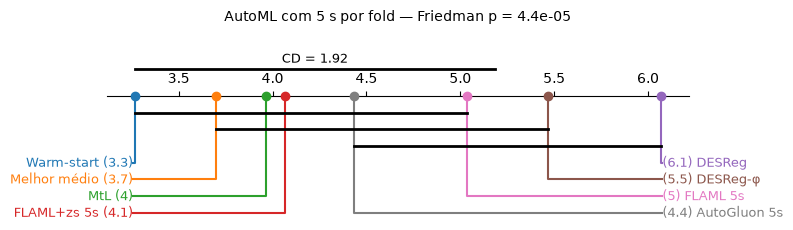

5s: p(MtL vs AutoML): {'autogluon_5s': np.float64(0.9959), 'flaml_5s': np.float64(0.6961), 'flaml_meta_5s': np.float64(1.0)}


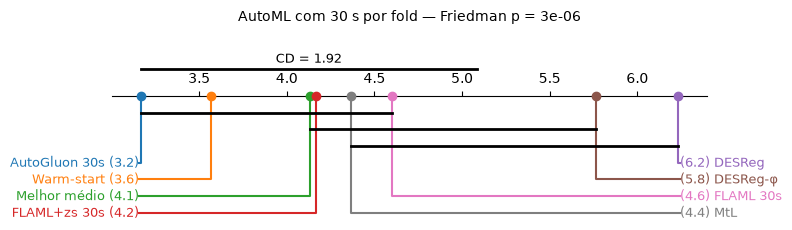

30s: p(MtL vs AutoML): {'autogluon_30s': np.float64(0.5527), 'flaml_30s': np.float64(1.0), 'flaml_meta_30s': np.float64(1.0)}


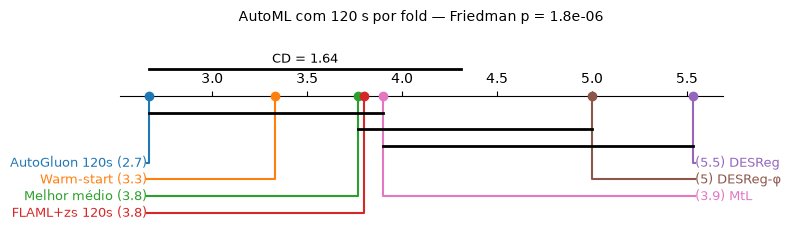

120s: p(MtL vs AutoML): {'autogluon_120s': np.float64(0.2893), 'flaml_meta_120s': np.float64(1.0)}


,orcamento,metodos,friedman,p,cd
0,5,8,31.8335,0.0,1.9169
1,30,8,37.9872,0.0,1.9169
2,120,7,36.9843,0.0,1.6445


In [7]:
ROT = {'Melhor_medio': 'Melhor médio', 'MtL': 'MtL', 'Warm-start': 'Warm-start',
       'DESReg': 'DESReg', 'DESReg_phi': 'DESReg-φ'}
def rotulo(m):
    if m in ROT: return ROT[m]
    s, o = m.rsplit('_', 1)
    return {'flaml': 'FLAML', 'flaml_meta': 'FLAML+zs', 'autogluon': 'AutoGluon'}[s] + f' {o}'

testes = []
for orc in [5, 30, 120]:
    cols = METODOS_FIXOS + [m for m in AUTOML if m.endswith(f'_{orc}s')]
    tab = L[cols]
    est, p = friedmanchisquare(*[tab[col] for col in cols])
    k, n = len(cols), len(tab)
    cd = studentized_range.ppf(0.95, k, np.inf) / np.sqrt(2) * np.sqrt(k * (k + 1) / (6 * n))
    pv = sp.posthoc_nemenyi_friedman(tab.to_numpy()); pv.index = pv.columns = cols
    ranks = tab.rank(axis=1).mean()
    testes.append(dict(orcamento=orc, metodos=k, friedman=est, p=p, cd=cd))
    plt.figure(figsize=(8, 2.4))
    sp.critical_difference_diagram(ranks.rename(rotulo), pv.rename(index=rotulo, columns=rotulo),
                                   label_props={'fontsize': 9})
    ax = plt.gca(); ini = ranks.min()
    ax.plot([ini, ini + cd], [1.6, 1.6], color='black', lw=2)
    ax.text(ini + cd / 2, 2.0, f'CD = {cd:.2f}', ha='center', fontsize=9); ax.set_ylim(top=3.0)
    plt.title(f'AutoML com {orc} s por fold — Friedman p = {p:.2g}', fontsize=10, pad=18)
    plt.tight_layout(); plt.savefig(FIG / f'cd_{orc}s.pdf', bbox_inches='tight'); plt.show()
    pv.to_csv(R / f'nemenyi_{orc}s.csv')
    print(f'{orc}s: p(MtL vs AutoML):', {m: round(pv.loc['MtL', m], 4) for m in cols if m not in METODOS_FIXOS})
testes = pd.DataFrame(testes); testes.to_csv(R / 'friedman.csv', index=False); display(testes.round(4))

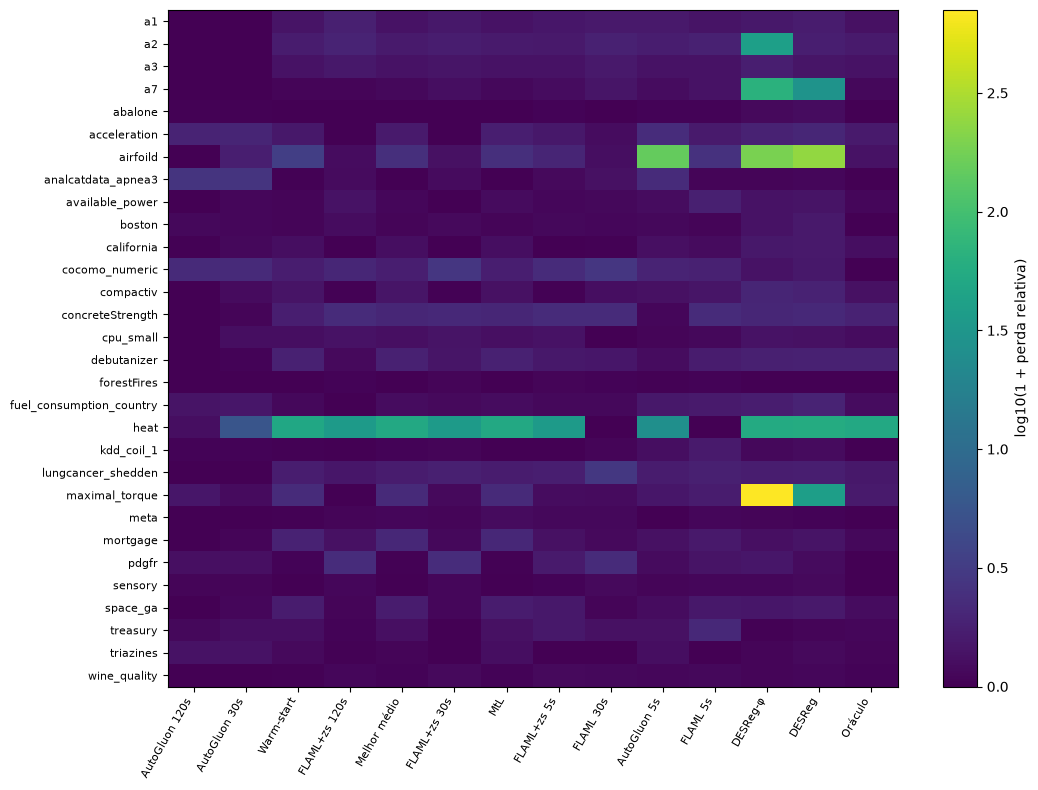

In [8]:
# Dataset a dataset: perda relativa de cada método (heatmap)
ordem = resumo.index.tolist()
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(np.log10(1 + REL[ordem].to_numpy()), aspect='auto', cmap='viridis')
ax.set_xticks(range(len(ordem)), [rotulo(m) if m != 'Oraculo' else 'Oráculo' for m in ordem], rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(DATASETS)), DATASETS, fontsize=8)
plt.colorbar(im, label='log10(1 + perda relativa)'); plt.tight_layout()
plt.savefig(FIG / 'perda_por_dataset.pdf', bbox_inches='tight'); plt.show()

## 4. Análise 2 — desempenho e custo

{'MtL': '0.26 h de CPU', 'Warm-start': '8.82 h de CPU'}


,segundos_por_fold,perda_rel_media,perda_rel_mediana,rank_medio
metodo,,,,
MtL,1.269,2.116,0.319,6.833
Melhor_medio,1.496,2.105,0.300,6.533
flaml_5s,5.739,0.484,0.434,8.350
autogluon_5s,8.334,6.216,0.308,7.567
flaml_meta_5s,8.756,1.516,0.288,7.083
autogluon_30s,26.169,0.413,0.123,5.033
flaml_30s,31.013,0.410,0.195,7.317
DESReg_phi,31.833,35.525,0.490,9.100
DESReg,31.839,12.561,0.551,9.700


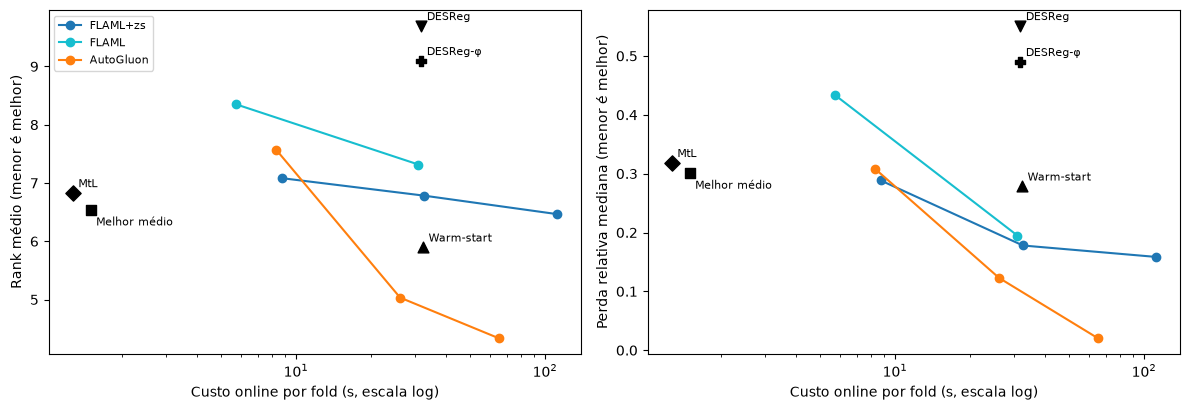

In [9]:
# Custo offline (segundos de CPU somados), do conjunto das práticas:
#  * MtL: construir P (6 regressores × 10 folds × 30 datasets, medido agora) e Xbase (30 extrações)
#  * Warm-start: matriz de perdas 60 × 30 da Prática 3 e extração de Xestendido (Prática 2)
custo_ext = pd.read_csv(c.BASE / 'pratica-02' / 'resultados' / 'custo_extracao.csv')
custo_ext = custo_ext[custo_ext.fase != 'nulo']           # distribuições nulas são diagnóstico, não descritor
t_xest = custo_ext.groupby('dataset').segundos.sum().reindex(DATASETS)
t_xbase = pd.Series({d: v['meta_caracteristicas'] for d, v in custo_rec.items()})
tempo_p3 = json.loads((c.P3 / 'tempo_matriz.json').read_text())
offline = {'MtL': base.segundos.sum() + t_xbase.sum(),
           'Warm-start': tempo_p3['segundos_ajustes'] + t_xest.sum()}
print({k: f'{v/3600:.2f} h de CPU' for k, v in offline.items()})

# Warm-start: o custo online inclui extrair Xestendido do alvo (rateado nos folds)
TEMPO['Warm-start'] = TEMPO['Warm-start'] + t_xest / c.FOLDS

custo = pd.DataFrame({'segundos_por_fold': TEMPO.drop(columns='Oraculo').mean(),
                      'perda_rel_media': REL.drop(columns='Oraculo').mean(),
                      'perda_rel_mediana': REL.drop(columns='Oraculo').median(),
                      'rank_medio': L.drop(columns='Oraculo').rank(axis=1).mean()})
display(custo.sort_values('segundos_por_fold').round(3))
custo.to_csv(R / 'custo_desempenho.csv')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for eixo, y, nome in [(ax[0], 'rank_medio', 'Rank médio (menor é melhor)'), (ax[1], 'perda_rel_mediana', 'Perda relativa mediana (menor é melhor)')]:
    for sis, cor in [('flaml_meta', 'C0'), ('flaml', 'C9'), ('autogluon', 'C1')]:
        sub = custo.loc[[m for m in AUTOML if m.rsplit('_', 1)[0] == sis]].sort_values('segundos_por_fold')
        eixo.plot(sub.segundos_por_fold, sub[y], 'o-', color=cor, label=rotulo(sub.index[0]).split()[0])
    for m, mk in zip(METODOS_FIXOS, ['s', 'D', '^', 'v', 'P']):
        eixo.scatter(custo.loc[m, 'segundos_por_fold'], custo.loc[m, y], marker=mk, s=60, color='k')
        eixo.annotate(rotulo(m), (custo.loc[m, 'segundos_por_fold'], custo.loc[m, y]), xytext=(4, -11 if m == 'Melhor_medio' else 4), textcoords='offset points', fontsize=8)
    eixo.set_xscale('log'); eixo.set_xlabel('Custo online por fold (s, escala log)'); eixo.set_ylabel(nome)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG / 'custo_desempenho.pdf', bbox_inches='tight'); plt.show()

In [10]:
# Com que orçamento o AutoML supera a MtL? Por dataset: menor orçamento em que a SERA média do AutoML < a da MtL.
supera = {}
for sis in ['flaml_meta', 'flaml', 'autogluon']:
    cols = [m for m in AUTOML if m.rsplit('_', 1)[0] == sis]
    for alvo in ['MtL', 'Warm-start']:
        primeiro = L[cols].lt(L[alvo], axis=0).idxmax(axis=1).where(L[cols].lt(L[alvo], axis=0).any(axis=1), 'nunca')
        supera[(sis, alvo)] = primeiro.value_counts().reindex(cols + ['nunca'], fill_value=0)
display(pd.DataFrame(supera).fillna(0).astype(int))

# Ponto de equilíbrio do custo offline: menor n de datasets novos com offline + online_sol × n ≤ online_AutoML × n.
# A comparação justa é com o AutoML de desempenho equivalente (rank médio parecido); contra AutoML
# melhores, a economia é troca de qualidade por custo, e não ganho líquido.
for sol in ['MtL', 'Warm-start']:
    for m in AUTOML:
        dif = (TEMPO[m].mean() - TEMPO[sol].mean()) * c.FOLDS        # por dataset (10 folds)
        if dif > 0:
            rel = 'melhor' if custo.loc[m, 'rank_medio'] < custo.loc[sol, 'rank_medio'] else 'pior'
            print(f'{sol} vs {rotulo(m)} (AutoML {rel} em rank): economia {dif:.0f} s/dataset, '
                  f'offline se paga após {int(np.ceil(offline[sol] / dif))} datasets novos')

flaml_meta            flaml            autogluon           
                       MtL Warm-start   MtL Warm-start       MtL Warm-start
autogluon_120s           0          0     0          0         0          2
autogluon_30s            0          0     0          0        10          8
autogluon_5s             0          0     0          0        10         10
flaml_30s                0          0     5          3         0          0
flaml_5s                 0          0    12         10         0          0
flaml_meta_120s          2          2     0          0         0          0
flaml_meta_30s           2          3     0          0         0          0
flaml_meta_5s           16         14     0          0         0          0
nunca                   10         11    13         17        10         10

MtL vs AutoGluon 5s (AutoML pior em rank): economia 71 s/dataset, offline se paga após 14 datasets novos
MtL vs AutoGluon 30s (AutoML melhor em rank): economia 249 s/dataset, offline se paga após 4 datasets novos
MtL vs AutoGluon 120s (AutoML melhor em rank): economia 642 s/dataset, offline se paga após 2 datasets novos
MtL vs FLAML 5s (AutoML pior em rank): economia 45 s/dataset, offline se paga após 21 datasets novos
MtL vs FLAML+zs 5s (AutoML pior em rank): economia 75 s/dataset, offline se paga após 13 datasets novos
MtL vs FLAML 30s (AutoML pior em rank): economia 297 s/dataset, offline se paga após 4 datasets novos
MtL vs FLAML+zs 30s (AutoML melhor em rank): economia 313 s/dataset, offline se paga após 3 datasets novos
MtL vs FLAML+zs 120s (AutoML melhor em rank): economia 1102 s/dataset, offline se paga após 1 datasets novos
Warm-start vs AutoGluon 120s (AutoML melhor em rank): economia 331 s/dataset, offline se paga após 96 datasets novos
Warm-start vs FLAML+zs 30s (AutoML pio

## 5. Análise 3 — o que o AutoML escolheu

In [11]:
FAMILIA = {'rf': 'RF', 'RandomForestMSE': 'RF', 'RandomForest': 'RF', 'lgbm': 'GB', 'xgboost': 'GB', 'xgb_limitdepth': 'GB',
           'catboost': 'GB', 'LightGBM': 'GB', 'LightGBMXT': 'GB', 'LightGBMLarge': 'GB', 'CatBoost': 'GB', 'XGBoost': 'GB',
           'extra_tree': 'ExtraTrees', 'ExtraTreesMSE': 'ExtraTrees', 'sgd': 'Linear', 'LinearModel': 'Linear',
           'KNeighborsUnif': 'KNN', 'KNeighborsDist': 'KNN', 'NeuralNetFastAI': 'Rede neural', 'NeuralNetTorch': 'Rede neural'}
def base_ag(m): return m.split('_BAG')[0].replace('_L1', '')

def familias(r):
    if r.sistema == 'autogluon' and isinstance(r.pesos_ensemble, dict) and r.pesos_ensemble:
        return sorted({FAMILIA.get(base_ag(k), k) for k in r.pesos_ensemble})
    return [FAMILIA.get(base_ag(r.modelo), r.modelo)]
automl['familias'] = automl.apply(familias, axis=1)
def modelo_base(r):
    # AutoGluon: um WeightedEnsemble com um único peso é, na prática, aquele modelo
    if r.sistema != 'autogluon':
        return base_ag(r.modelo)
    if r.ensemble:
        return 'WeightedEnsemble'
    pesos = r.pesos_ensemble if isinstance(r.pesos_ensemble, dict) and r.pesos_ensemble else {r.modelo: 1}
    return base_ag(next(iter(pesos)))
automl['modelo_base'] = automl.apply(modelo_base, axis=1)

display(automl.groupby('metodo').modelo_base.value_counts(normalize=True).unstack(fill_value=0).round(2))
ag = automl[automl.sistema == 'autogluon']
print('AutoGluon: fração de folds com ensemble de >1 modelo:', ag.ensemble.astype(float).groupby(ag.orcamento).mean().round(2).to_dict())
print('AutoGluon: modelos por ensemble (média):', ag.groupby('orcamento').pesos_ensemble.apply(lambda s: np.mean([len(p) if isinstance(p, dict) else 1 for p in s])).round(2).to_dict())

exp = automl.explode('familias')
# fração de folds em que cada família aparece no modelo final (um ensemble pode ter várias)
freq = pd.crosstab([exp.metodo, exp.dataset, exp.fold], exp.familias).clip(upper=1).groupby('metodo').mean()
print('fração de folds em que a família aparece no modelo final:'); display(freq.round(2))
fora_de_P = automl.familias.apply(lambda f: bool(set(f) - set(c.ALGORITMOS))).groupby(automl.metodo).mean()
print('fração de folds com alguma família fora dos 6 algoritmos de P:'); display(fora_de_P.round(2))

concorda = exp.assign(rec=exp.dataset.map(rec)).assign(igual=lambda d: d.familias == d.rec).groupby(['metodo', 'dataset', 'fold']).igual.any().groupby('metodo').mean()
print('fração de folds em que a família recomendada pela MtL aparece no modelo final do AutoML:'); display(concorda.round(2))

modelo_base,CatBoost,ExtraTreesMSE,LightGBM,LightGBMLarge,LightGBMXT,NeuralNetFastAI,NeuralNetTorch,RandomForestMSE,WeightedEnsemble,catboost,extra_tree,lgbm,rf,sgd,xgb_limitdepth,xgboost
metodo,,,,,,,,,,,,,,,,
autogluon_120s,0.02,0.01,0.03,0.01,0.04,0.01,0.04,0.00,0.83,0.00,0.00,0.00,0.00,0.00,0.00,0.00
autogluon_30s,0.00,0.01,0.11,0.01,0.23,0.01,0.04,0.00,0.58,0.00,0.00,0.00,0.00,0.00,0.00,0.00
autogluon_5s,0.01,0.00,0.10,0.00,0.55,0.02,0.00,0.04,0.27,0.00,0.00,0.00,0.00,0.00,0.00,0.00
flaml_30s,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.16,0.03,0.32,0.03,0.06,0.15,0.26
flaml_5s,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.22,0.03,0.42,0.04,0.05,0.02,0.22
flaml_meta_120s,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.05,0.11,0.38,0.04,0.06,0.08,0.27
flaml_meta_30s,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.06,0.12,0.41,0.03,0.05,0.07,0.27
flaml_meta_5s,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.09,0.08,0.46,0.04,0.04,0.06,0.24


AutoGluon: fração de folds com ensemble de >1 modelo: {5: 0.27, 30: 0.58, 120: 0.83}
AutoGluon: modelos por ensemble (média): {5: 1.38, 30: 1.87, 120: 2.38}
fração de folds em que a família aparece no modelo final:


familias,ExtraTrees,GB,Linear,RF,Rede neural
metodo,,,,,
autogluon_120s,0.15,0.84,0.00,0.21,0.65
autogluon_30s,0.11,0.87,0.00,0.21,0.41
autogluon_5s,0.09,0.89,0.00,0.20,0.15
flaml_30s,0.03,0.89,0.06,0.03,0.00
flaml_5s,0.03,0.89,0.05,0.04,0.00
flaml_meta_120s,0.11,0.79,0.06,0.04,0.00
flaml_meta_30s,0.12,0.80,0.05,0.03,0.00
flaml_meta_5s,0.08,0.84,0.04,0.04,0.00


fração de folds com alguma família fora dos 6 algoritmos de P:


metodo
autogluon_120s     0.69
autogluon_30s      0.45
autogluon_5s       0.19
flaml_30s          0.03
flaml_5s           0.03
flaml_meta_120s    0.11
flaml_meta_30s     0.12
flaml_meta_5s      0.08
Name: familias, dtype: float64

fração de folds em que a família recomendada pela MtL aparece no modelo final do AutoML:


metodo
autogluon_120s     0.38
autogluon_30s      0.36
autogluon_5s       0.38
flaml_30s          0.25
flaml_5s           0.25
flaml_meta_120s    0.15
flaml_meta_30s     0.16
flaml_meta_5s      0.19
Name: igual, dtype: float64

In [12]:
# Pré-processamento: o FLAML não faz engenharia de atributos para dados numéricos; o AutoGluon aplica
# seu gerador de atributos automático (todos os 30 datasets são numéricos, então ele só tipa/remove constantes).
# Onde o AutoML mais ganhou da MtL, e o que já sabíamos desses datasets?
ref = 'flaml_meta_120s' if 'flaml_meta_120s' in L else AUTOML[-1]
# AutoGluon a 120 s sozinho: escolher o melhor AutoML por dataset olharia o teste
ganho = (L['MtL'] - L['autogluon_120s']) / L['MtL']
dist = pd.read_csv(c.P3 / 'distancias.csv').query("meta == 'estendido'").set_index('dataset').distancia
p1 = pd.read_csv(c.BASE / 'pratica-01' / 'resultados' / 'avaliacao_por_dataset.csv').query("abordagem == 'Abordagem_2'").set_index('dataset')
tab = pd.DataFrame({'ganho_rel_AutoGluon_120s': ganho,
                    'MtL_acertou_oraculo': rec == oraculo,
                    'perda_meta_modelo_P1': p1.perda_t1,
                    'distancia_vizinho_P3': dist,
                    'pct_relevante': Xbase.pct_relevante, 'n': Xbase.n_instances, 'p': Xbase.n_features,
                    'oraculo_vs_MtL': L['MtL'] / L['Oraculo'] - 1,
                    'automl_vs_oraculo': L['autogluon_120s'] / L['Oraculo'] - 1}).loc[DATASETS]
display(tab.sort_values('ganho_rel_AutoGluon_120s', ascending=False).round(3))
for col in ['perda_meta_modelo_P1', 'distancia_vizinho_P3', 'pct_relevante', 'n', 'p']:
    rho, p = spearmanr(tab.ganho_rel_AutoGluon_120s, tab[col], nan_policy='omit')
    print(f'Spearman ganho × {col}: rho={rho:.3f}, p={p:.3g}')
print('Datasets em que o AutoGluon 120 s supera o ORÁCULO dos 6 algoritmos:', int((tab.automl_vs_oraculo < 0).sum()), 'de 30',
      '| ganho mediano sobre o oráculo:', round(float(-tab.automl_vs_oraculo.median()), 3))
tab.to_csv(R / 'ganho_automl_por_dataset.csv')

,ganho_rel_AutoGluon_120s,MtL_acertou_oraculo,perda_meta_modelo_P1,distancia_vizinho_P3,pct_relevante,n,p,oraculo_vs_MtL,automl_vs_oraculo
heat,0.976,True,0.000,4.914,0.090,7400,11,0.000,-0.976
airfoild,0.585,False,0.000,7.727,0.107,1503,5,0.740,-0.278
mortgage,0.523,False,0.344,0.767,0.101,1049,15,0.826,-0.129
concreteStrength,0.501,False,0.027,4.378,0.053,1030,8,0.082,-0.460
debutanizer,0.452,True,0.000,5.085,0.100,2394,7,0.000,-0.452
space_ga,0.396,False,0.406,370.289,0.056,3107,6,0.326,-0.199
lungcancer_shedden,0.391,False,0.116,4.349,0.057,442,24,0.065,-0.352
a2,0.384,True,0.000,4.852,0.111,198,11,0.000,-0.384
maximal_torque,0.315,False,0.000,2.957,0.072,1802,32,0.352,-0.074
a3,0.283,False,0.000,5.859,0.162,198,11,0.016,-0.272


Spearman ganho × perda_meta_modelo_P1: rho=0.103, p=0.588
Spearman ganho × distancia_vizinho_P3: rho=-0.172, p=0.362
Spearman ganho × pct_relevante: rho=-0.449, p=0.0128
Spearman ganho × n: rho=0.348, p=0.0592
Spearman ganho × p: rho=-0.441, p=0.0147
Datasets em que o AutoGluon 120 s supera o ORÁCULO dos 6 algoritmos: 18 de 30 | ganho mediano sobre o oráculo: 0.083


## 6. Meta-conhecimento dentro do AutoML e sobreposição com os nossos datasets

In [13]:
# FLAML com e sem o portfólio zero-shot, no mesmo orçamento
for orc in [5, 30, 120]:
    a, b = f'flaml_meta_{orc}s', f'flaml_{orc}s'
    if a in L and b in L:
        d = (L[b] - L[a]) / L[b]
        print(f'{orc}s: zero-shot melhor em {(d > 0).sum()}/30 datasets; ganho relativo mediano {d.median():+.3f}')

# Quantos estimadores receberam configuração zero-shot efetiva (diferente do ponto estático)?
fm = automl[automl.sistema == 'flaml_meta'].copy()
estaticos = automl[automl.sistema == 'flaml'].set_index(['dataset', 'fold', 'orcamento']).iniciais
def efetivos(r):
    est = estaticos.get((r.dataset, r.fold, r.orcamento))
    if not isinstance(est, dict): return np.nan
    return sum(json.dumps(r.iniciais.get(e), sort_keys=True, default=str) != json.dumps(est.get(e), sort_keys=True, default=str) for e in r.iniciais)
fm['zero_shot_efetivos'] = fm.apply(efetivos, axis=1)
print('estimadores com ponto inicial zero-shot efetivo (média por fold):')
display(fm.groupby('dataset').zero_shot_efetivos.mean().sort_values(ascending=False).head(10))
print('primeiro estimador da busca (sugerido pelo zero-shot):', fm.ordem_estimadores.str[0].value_counts().to_dict())

5s: zero-shot melhor em 19/30 datasets; ganho relativo mediano +0.019
30s: zero-shot melhor em 18/30 datasets; ganho relativo mediano +0.025
estimadores com ponto inicial zero-shot efetivo (média por fold):


dataset
compactiv          4.0
wine_quality       3.0
acceleration       3.0
available_power    3.0
cpu_small          3.0
heat               3.0
treasury           2.0
mortgage           2.0
boston             2.0
california         2.0
Name: zero_shot_efetivos, dtype: float64

primeiro estimador da busca (sugerido pelo zero-shot): {'lgbm': 540, 'xgboost': 240, 'xgb_limitdepth': 90, 'extra_tree': 30}


In [14]:
# O portfólio do FLAML foi minerado em datasets do OpenML/AMLB. Os nomes das configurações e os
# 22 vizinhos (meta-características em escala original) permitem checar a sobreposição.
import flaml, os
port = json.load(open(Path(flaml.__file__).parent / 'default' / 'all' / 'regression.json'))
centro, escala = np.array(port['preprocessing']['center']), np.array(port['preprocessing']['scale'])
viz = pd.DataFrame([np.array(v['features']) * escala + centro for v in port['neighbors']], columns=port['meta_feature_names'])
viz[['NumberOfInstances', 'NumberOfFeatures']] = viz[['NumberOfInstances', 'NumberOfFeatures']].round().astype(int)
print('configurações do portfólio (estimador/dataset de origem):', port['configsource'])
# As meta-características do portfólio foram medidas no treino (90% do dataset, como nos nossos folds):
# comparamos com 0,9 × n e também com n.
nossos = Xbase[['n_instances', 'n_features']]
casam = []
for d, r in nossos.iterrows():
    for fator in (1.0, 0.9):
        perto = (viz.NumberOfInstances - fator * r.n_instances).abs() / (fator * r.n_instances) < 0.005
        if (perto & (viz.NumberOfFeatures == r.n_features)).any():
            casam.append((d, int(r.n_instances), int(r.n_features), fator))
print('datasets nossos com ponto do portfólio de mesmo n (±0,5%, n ou 0,9n) e mesmo p:', casam)
display(viz.sort_values('NumberOfInstances'))

configurações do portfólio (estimador/dataset de origem): ['lgbm/houses', 'lgbm/house_8L', 'lgbm/poker', 'lgbm/default', 'xgboost/Albert', 'xgboost/mv', 'xgboost/bng_echomonths', 'xgboost/house_16H', 'xgb_limitdepth/higgs', 'xgb_limitdepth/bng_pharynx', 'xgb_limitdepth/connect-4', 'xgb_limitdepth/house_16H', 'xgb_limitdepth/bng_echomonths', 'xgb_limitdepth/default', 'rf/houses', 'rf/poker', 'rf/bank-marketing', 'rf/default', 'extra_tree/house_16H', 'extra_tree/default', 'extra_tree/dilbert', 'extra_tree/particulate-matter']
datasets nossos com ponto do portfólio de mesmo n (±0,5%, n ou 0,9n) e mesmo p: [('california', 20640, 8, 0.9)]


,NumberOfInstances,NumberOfFeatures,NumberOfClasses,PercentageOfNumericFeatures
11,9622,12,0.0,0.666667
2,12375,40,0.0,1.000000
20,13500,48,0.0,1.000000
21,15079,3,0.0,0.333333
5,15746,9,0.0,0.666667
15,18576,8,0.0,1.000000
14,20505,8,0.0,1.000000
13,20505,16,0.0,1.000000
7,27993,9,0.0,0.222222
16,36691,10,0.0,0.700000
